# 05 – Ziel-Bibliothek und PGDAA

PGDA (Wang et al. 2022, *Prior-Guided Data Augmentation for Infrared Small Target Detection*) schneidet
die Ziele **über ihre Pixelmaske** aus und fügt sie mit Gauß-gewichteter Maske („Gaussian paste“) und an
die SCR-Verteilung angepasster Intensität („SCR perception“) wieder ein. Unsere Datensätze haben nur Boxen.

Ersatz: eine **Bibliothek der Ziele aller Datensätze** (train). Jedes Ziel bekommt eine
Pseudo-Maske aus dem lokalen Kontrast: Schwelle innerhalb der Box gegen den Hintergrundring wie bei
der SCR-Berechnung (Radius d = 20). Der Hintergrund des Ausschnitts ist schwarz und transparent.

1. Tags in `IR_label.json`: Bedeutung und Anteil
2. Filter-Trichter: welche Frames werden Kandidaten?
3. Segmentierung prüfen (Pseudo-Maske, Parameter)
4. Bibliothek bauen → `data/library/`
5. Bibliothek analysieren (Verteilungen gegen den ganzen Train-Split, Galerie)
6. Vorschau: Gaussian paste auf Train-Frames
7. PGDAA: Prioren A und S, synthetische Bilder, Ablation

Code: `src/data_handler/target_library.py` (Bau) und `src/augmentations/sota.py` (Lesen, Gaussian Paste). Die Bibliothek nutzt den **train**-Split aller Datensätze
(Augmentierung, also kein val/test); `DATASETS` aus `00_utils` gilt hier nicht. Abschnitte 1–3 analysieren die
Tags von Anti-UAV410 (nur dort gibt es Tags).

In [2]:
%run 00_utils.ipynb

%load_ext autoreload
%autoreload 2

Root-Verzeichnis: /home/jessh/Study/Bachelor-Thesis
Datensätze: Anti-UAV410 + CST-AntiUAV


In [3]:
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import LIBRARY_DIR
from data_handler.sources import load_dataset_split
from data_handler.target_library import (
    TAG_KEYS, TAG_NAMES, SIZE_KEY, SIZE_CLASSES, LibraryConfig, size_class, load_frame_tags, tag_table,
    select_candidates, local_contrast, segment_target, build_library,
)
from augmentations.sota import load_library, read_cutout, gaussian_paste, PGDAA

DS = DatasetName.ANTI_UAV_410  # Tag-Analyse (Abschnitte 1-3, Vergleich in 5)
CFG = LibraryConfig()  # Standardwerte; ändern z.B. mit LibraryConfig(min_scr=4.0, rel_thresh=0.3)
SEED = 0
CFG

LibraryConfig(datasets=(<DatasetName.ANTI_UAV_410: 'Anti-UAV410'>, <DatasetName.CST_ANTI_UAV: 'CST-AntiUAV'>), split='train', require_tags=False, exclude_tags=(), size_classes=(0, 1, 2, 3), hud_rows=96, stride=10, max_per_seq=100, d=20, gap=2, sigma_floor=1.0, min_scr=5.0, k_sigma=3.0, rel_thresh=0.2, box_tol=2, min_component_frac=0.25, min_mask_px=4, fill_range=(0.05, 0.9), pad=2)

In [4]:
# ---------------------------------------------------------
# Hilfsfunktionen für die Darstellung
# ---------------------------------------------------------
def read_gray(path):
    return cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)


def crop_around(img, box, margin=40):
    # Ausschnitt Box ± margin und die Box in Ausschnitt-Koordinaten
    x, y, w, h = box
    H, W = img.shape[:2]
    x0, y0 = max(int(x - margin), 0), max(int(y - margin), 0)
    x1, y1 = min(int(x + w + margin), W), min(int(y + h + margin), H)
    return img[y0:y1, x0:x1], (x - x0, y - y0, w, h)


def draw_box(ax, box, color="lime", lw=0.8):
    x, y, w, h = box
    ax.add_patch(plt.Rectangle((x - 0.5, y - 0.5), w, h, fill=False, ec=color, lw=lw))


def overlay(gray, mask, color=(1.0, 0.0, 0.0), alpha=0.5):
    # Graubild mit eingefärbter Maske (RGB, float)
    rgb = np.dstack([gray] * 3).astype(np.float32) / 255
    if mask is not None:
        rgb[mask] = (1 - alpha) * rgb[mask] + alpha * np.asarray(color)
    return rgb


def on_checkerboard(gray, mask):
    # Ausschnitt auf farbigem Schachbrett = transparenter Hintergrund (Ziel bleibt grau, also unterscheidbar)
    tile = max(1, min(gray.shape) // 6)
    yy, xx = np.indices(gray.shape)
    even = (((yy // tile) + (xx // tile)) % 2 == 0)[..., None]
    board = np.where(even, (1.0, 0.75, 0.85), (0.75, 0.85, 1.0))
    return np.where(mask[..., None], np.dstack([gray] * 3) / 255, board)


def per_seq_sample(df, n_per_seq):
    # Bis zu n_per_seq Frames je Sequenz, gleichmäßig verteilt (deterministisch)
    out = []
    for _, g in df.groupby("seq", sort=True):
        idx = np.unique(np.linspace(0, len(g) - 1, min(n_per_seq, len(g))).round().astype(int))
        out.append(g.iloc[idx])
    return pd.concat(out, ignore_index=True)


def add_contrast(df, cfg=CFG):
    # Spalten scr_peak + polarity per local_contrast (= scr_extreme in 06_measure.ipynb)
    res = []
    for r in df.itertuples(index=False):
        c = local_contrast(read_gray(r.img_path), (r.x, r.y, r.w, r.h), cfg.d, cfg.gap, cfg.sigma_floor, cfg.hud_rows)
        res.append((c.scr_peak, "hell" if c.polarity > 0 else "dunkel") if c else (np.nan, None))
    return df.assign(scr_peak=[a for a, _ in res], polarity=[b for _, b in res])

## 1. Tags in Anti-UAV410

Jeder Frame hat in `IR_label.json` die Schlüssel `LR, VE, OC, FM, SV, IC, DBC` (0/1) und `TS`
(Größenklasse 0–3). Das offizielle README (github.com/HwangBo94/Anti-UAV410) nennt die Attribute
Thermal Crossover (TC), Out-of-View (OV), Scale Variation (SV), Fast Motion (FM), Occlusion (OC),
Dynamic Background Clutter (DBC) und vier Größenklassen (Tiny/Small/Medium/Normal). Daraus folgt:

| Schlüssel | Bedeutung |
|---|---|
| OC | Okklusion |
| FM | schnelle Bewegung |
| SV | Skalenänderung |
| DBC | dynamischer Hintergrund-Clutter |
| TS | Größenklasse, gemessen auf √(w·h): ≤ 10, ≤ 30, ≤ 50, > 50 px |
| LR, VE, IC | **nicht dokumentiert**; Thermal Crossover heißt im README „TC“ und ist kein Schlüssel hier |

Weil drei Schlüssel nicht dokumentiert sind, schließt der Standard **jeden** gesetzten Tag aus
(„lieber sicher“). Die Beispielbilder und die Kontrast-Tabelle unten ordnen VE und IC aus den Daten ein.

In [5]:
tags = {split: load_frame_tags(DS.root / split) for split in ("train", "val", "test")}
pd.DataFrame([{"Split": s, "Sequenzen": len(t), "mit Tags": sum(v is not None for v in t.values()),
               "ohne Tags": sum(v is None for v in t.values())} for s, t in tags.items()])

,Split,Sequenzen,mit Tags,ohne Tags
0,train,200,47,153
1,val,90,17,73
2,test,120,30,90


Ohne Tags sind vor allem die älteren Aufnahmen `2019092*`: die Schlüssel sind da, die Listen leer.
Sie werden standardmäßig nicht verwendet (`require_tags=True`).

In [6]:
records = load_dataset_split(DS, "train")
train = pd.DataFrame(
    [(r.seq, r.frame_idx, r.img_path, *(r.bbox if r.bbox is not None else (np.nan,) * 4)) for r in records],
    columns=["seq", "frame_idx", "img_path", "x", "y", "w", "h"],
)
train["has_box"] = train.w.notna()
train["tagged"] = train.seq.map(lambda s: tags["train"].get(s) is not None)
train = train.merge(tag_table(tags["train"]), on=["seq", "frame_idx"], how="left")

tagged = train[train.tagged & train.has_box].copy()
tagged["clean"] = tagged[list(TAG_KEYS)].sum(axis=1) == 0
print(f"Train: {len(train)} Frames, {int(train.has_box.sum())} mit Ziel, davon {len(tagged)} in getaggten "
      f"Sequenzen und {int(tagged.clean.sum())} ohne gesetzten Tag")

24-11-2026 21:32:48 | INFO    | [train] Anti-UAV410: 213995 frames in 200 sequences (2.5 s)


Train: 213995 Frames, 208832 mit Ziel, davon 66908 in getaggten Sequenzen und 28996 ohne gesetzten Tag


In [7]:
keys = list(TAG_KEYS)
pd.DataFrame({
    "Bedeutung": pd.Series(TAG_NAMES),
    "Frames mit Tag": tagged[keys].sum(),
    "Anteil (%)": (100 * tagged[keys].mean()).round(1),
    "Sequenzen mit Tag": tagged.groupby("seq")[keys].max().sum(),
}).loc[keys]

,Bedeutung,Frames mit Tag,Anteil (%),Sequenzen mit Tag
LR,undokumentiert (immer 0),0.0,0.0,0.0
VE,"undokumentiert, gemessen: Ziel nicht sichtbar",53.0,0.1,8.0
OC,Okklusion,618.0,0.9,13.0
FM,schnelle Bewegung,7776.0,11.6,29.0
SV,Skalenänderung,460.0,0.7,4.0
IC,"undokumentiert, gemessen: geringer Kontrast",14661.0,21.9,34.0
DBC,dynamischer Hintergrund-Clutter,25740.0,38.5,35.0


In [8]:
# TS gegen die Boxgröße: size_class(w, h) reproduziert TS
tagged["sqrt_area"] = np.sqrt(tagged.w * tagged.h)
print(f"size_class(w, h) == TS: {(size_class(tagged.w, tagged.h) == tagged[SIZE_KEY]).mean():.2%}")
tagged.groupby(SIZE_KEY).sqrt_area.describe(percentiles=[.1, .5, .9]).round(1).rename(index=SIZE_CLASSES)

size_class(w, h) == TS: 100.00%


,count,mean,std,min,10%,50%,90%,max
TS,,,,,,,,
<=10 px,25324.0,8.3,1.2,3.9,6.5,8.5,9.8,10.0
10-30 px,39407.0,16.1,4.6,10.1,11.0,15.0,23.0,30.0
30-50 px,1713.0,35.9,4.4,30.0,30.8,34.9,42.3,49.8
>50 px,464.0,74.6,16.6,50.1,58.3,67.3,105.9,125.6


### Beispiele je Tag

Je Tag bis zu 8 Frames aus verschiedenen Sequenzen, Ausschnitt Box ± 40 px. Zum Vergleich zuerst Frames ohne Tag.

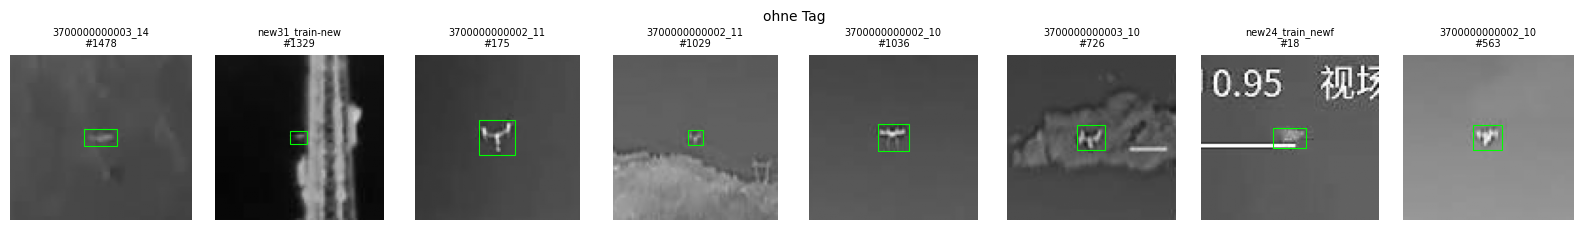

LR = 1 (undokumentiert (immer 0)): keine Frames


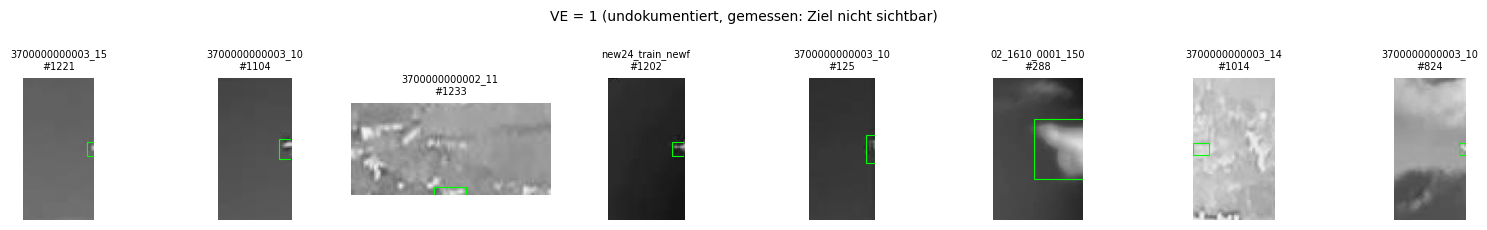

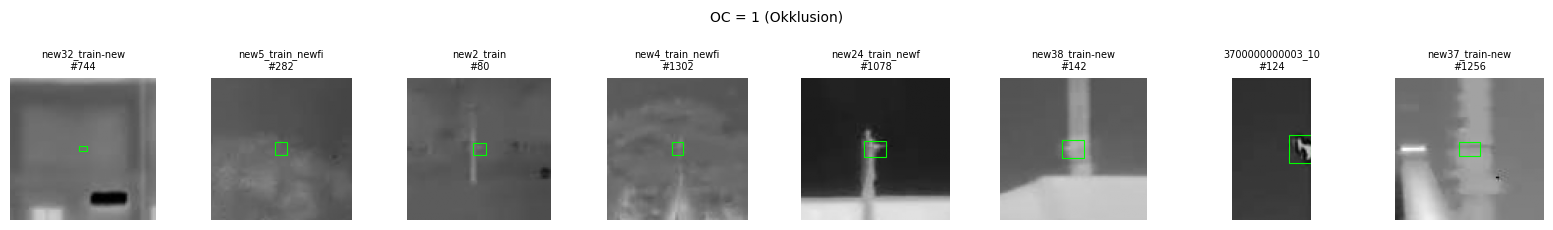

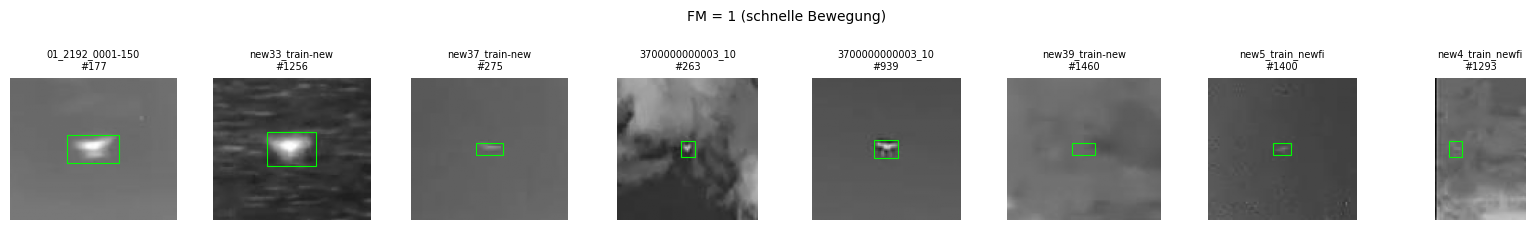

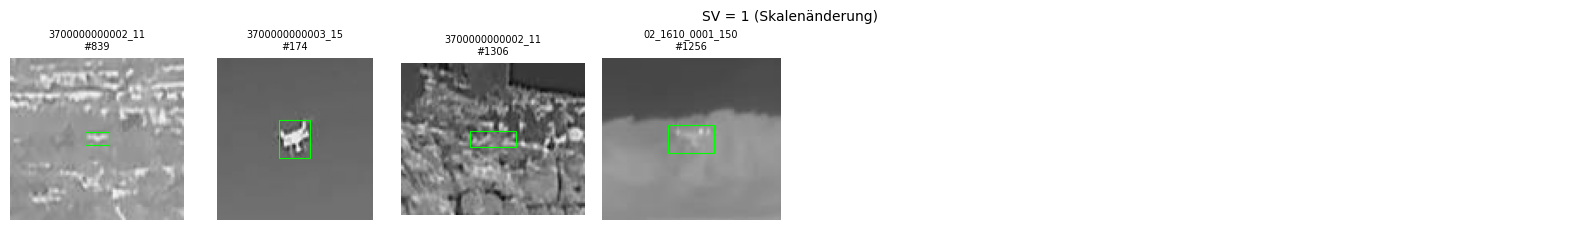

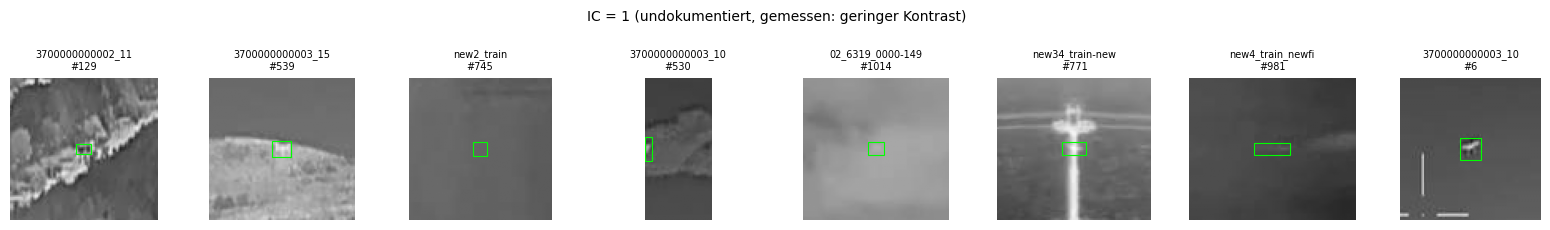

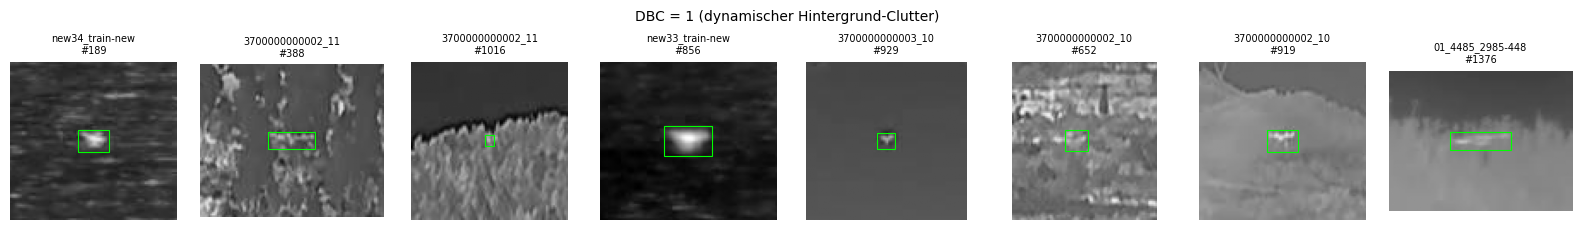

In [9]:
def show_examples(df, title, n=8, margin=40, seed=SEED):
    if df.empty:
        print(f"{title}: keine Frames")
        return
    rows = df.groupby("seq").sample(1, random_state=seed)
    rows = rows.sample(min(n, len(rows)), random_state=seed)
    fig, axes = plt.subplots(1, n, figsize=(2 * n, 2.3))
    for ax in axes:
        ax.axis("off")
    for ax, r in zip(axes, rows.itertuples(index=False)):
        crop, box = crop_around(read_gray(r.img_path), (r.x, r.y, r.w, r.h), margin)
        ax.imshow(crop, cmap="gray", vmin=0, vmax=255)
        draw_box(ax, box)
        ax.set_title(f"{r.seq[:16]}\n#{r.frame_idx}", fontsize=7)
    fig.suptitle(title, fontsize=10)
    plt.tight_layout()
    plt.show()


show_examples(tagged[tagged.clean], "ohne Tag")
for k in TAG_KEYS:
    show_examples(tagged[tagged[k] == 1], f"{k} = 1 ({TAG_NAMES[k]})")

### Kontrast je Tag

Peak-SCR = |Extremwert in der Box − μ_b| / σ_b, Hintergrundring d = 20 ohne Box ± 2 px und ohne HUD-Zeilen
(wie `scr_extreme` in `06_measure.ipynb`). Je Gruppe 15 Frames pro Sequenz. Niedriger SCR heißt: das Ziel hebt
sich kaum vom Hintergrund ab.

In [10]:
groups = {"ohne Tag": tagged[tagged.clean], **{k: tagged[tagged[k] == 1] for k in TAG_KEYS}}
rows = []
for name, g in groups.items():
    if g.empty:
        continue
    s = add_contrast(per_seq_sample(g, 15))
    rows.append({"Gruppe": name, "n": len(s), "Sequenzen": s.seq.nunique(), "SCR Median": s.scr_peak.median(),
                 f"SCR < {CFG.min_scr:g} (%)": 100 * (s.scr_peak < CFG.min_scr).mean(),
                 "dunkel (%)": 100 * (s.polarity == "dunkel").mean()})
pd.DataFrame(rows).round(1)

,Gruppe,n,Sequenzen,SCR Median,SCR < 5 (%),dunkel (%)
0,ohne Tag,568,38,15.1,24.8,12.3
1,VE,53,8,13.7,37.7,1.9
2,OC,117,13,2.4,83.8,18.8
3,FM,411,29,9.5,36.3,13.1
4,SV,46,4,4.1,63.0,6.5
5,IC,463,34,2.9,77.5,16.4
6,DBC,501,35,6.6,40.7,4.0


In [11]:
# VE gegen das Vorhandensein eines Ziels (alle Frames der getaggten Sequenzen, auch ohne Ziel)
pd.crosstab(train[train.tagged].VE, train[train.tagged].has_box.map({True: "Ziel da", False: "kein Ziel"}))

has_box,Ziel da,kein Ziel
VE,,
0.0,66855,0
1.0,53,2888


**Einordnung aus den Daten** (gemessen, nicht dokumentiert):

- **VE** ist bei jedem Frame ohne Ziel gesetzt und nur bei wenigen Frames mit Ziel, also praktisch das
  Out-of-View-Attribut (Ziel nicht sichtbar oder verlässt das Bild).
- **IC** hat den niedrigsten Kontrast aller Tags (Median-SCR um 3, rund drei Viertel unter `min_scr`). Die Beispiele
  zeigen Ziele vor Gebäuden, Bewuchs und Strukturen. Das passt zu Thermal Crossover (TC im README).
- **OC** und **SV** haben ebenfalls niedrigen Kontrast, **FM** und **DBC** mittleren.

Alle Tags auszuschließen bleibt damit richtig. Auch Frames ohne Tag haben aber teils niedrigen SCR, deshalb
prüft die Segmentierung zusätzlich `min_scr`.

## 2. Filter-Trichter

`select_candidates` zählt die Frames nach jedem Schritt (hier für Anti-UAV410; der Bau läuft je Datensatz):

1. `with_target`: Frame hat eine Box
2. `tagged_sequence`: Sequenz hat Tags (nur mit `require_tags=True`; Standard: aus)
3. `no_excluded_tag`: kein Tag aus `exclude_tags` gesetzt (Standard: keiner ausgeschlossen, PGDA nutzt alle Ziele)
4. `size_class`: TS in `size_classes` (Standard: alle)
5. `clear_of_hud_and_border`: Fenster Box ± d beginnt unterhalb des HUD-Bands (Zeile 96), Box berührt den Bildrand nicht
6. `thinned`: je Sequenz jeder `stride`-te saubere Frame, dann höchstens `max_per_seq` gleichmäßig verteilt
   (Nachbar-Frames sind fast identisch, und jede Sequenz soll ähnlich viel beitragen)

In [12]:
candidates, funnel = select_candidates(records, tags["train"], CFG)
f = pd.Series(funnel, name="Frames").to_frame()
f["Anteil vom Vorschritt (%)"] = (100 * f.Frames / f.Frames.shift()).round(1)
f

24-11-2026 21:32:54 | INFO    | Candidates: frames 213995 -> with_target 208832 -> no_excluded_tag 208832 -> size_class 208832 -> clear_of_hud_and_border 203681 -> thinned 18641 (200 sequences)


,Frames,Anteil vom Vorschritt (%)
frames,213995,NaN
with_target,208832,97.6
no_excluded_tag,208832,100.0
size_class,208832,100.0
clear_of_hud_and_border,203681,97.5
thinned,18641,9.2


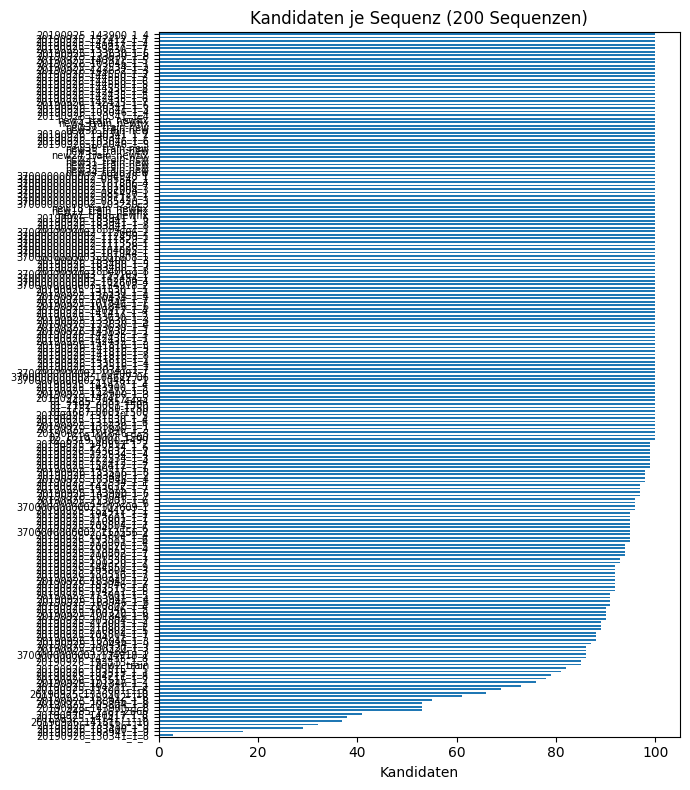

In [13]:
per_seq = pd.Series([c.record.seq for c in candidates]).value_counts().sort_values()
ax = per_seq.plot.barh(figsize=(7, 8), title=f"Kandidaten je Sequenz ({len(per_seq)} Sequenzen)")
ax.set_xlabel("Kandidaten")
ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

## 3. Segmentierung prüfen

Pseudo-Maske in `segment_target`:

- Kontrast mit Vorzeichen `s = pol · (I − μ_b)` (pol = +1 helles, −1 dunkles Ziel)
- Vordergrund: `s > max(k_sigma · σ_b, rel_thresh · Peak)`, nur in Box ± `box_tol`
- Closing 3×3, Blob mit dem Peak-Pixel (+ Blobs ≥ `min_component_frac` davon), Löcher füllen

Verworfen wird bei `low_scr` (Peak-SCR < `min_scr`), `tiny_mask` (< `min_mask_px`) und `fill_low` / `fill_high`
(Maske / Boxfläche außerhalb `fill_range`; zu hoch heißt, dass Hintergrund in die Maske gelaufen ist).

Spalten: Kontext mit Box | Maske (rot) | Ausschnitt auf Schwarz | Ausschnitt auf Schachbrett (= transparent).

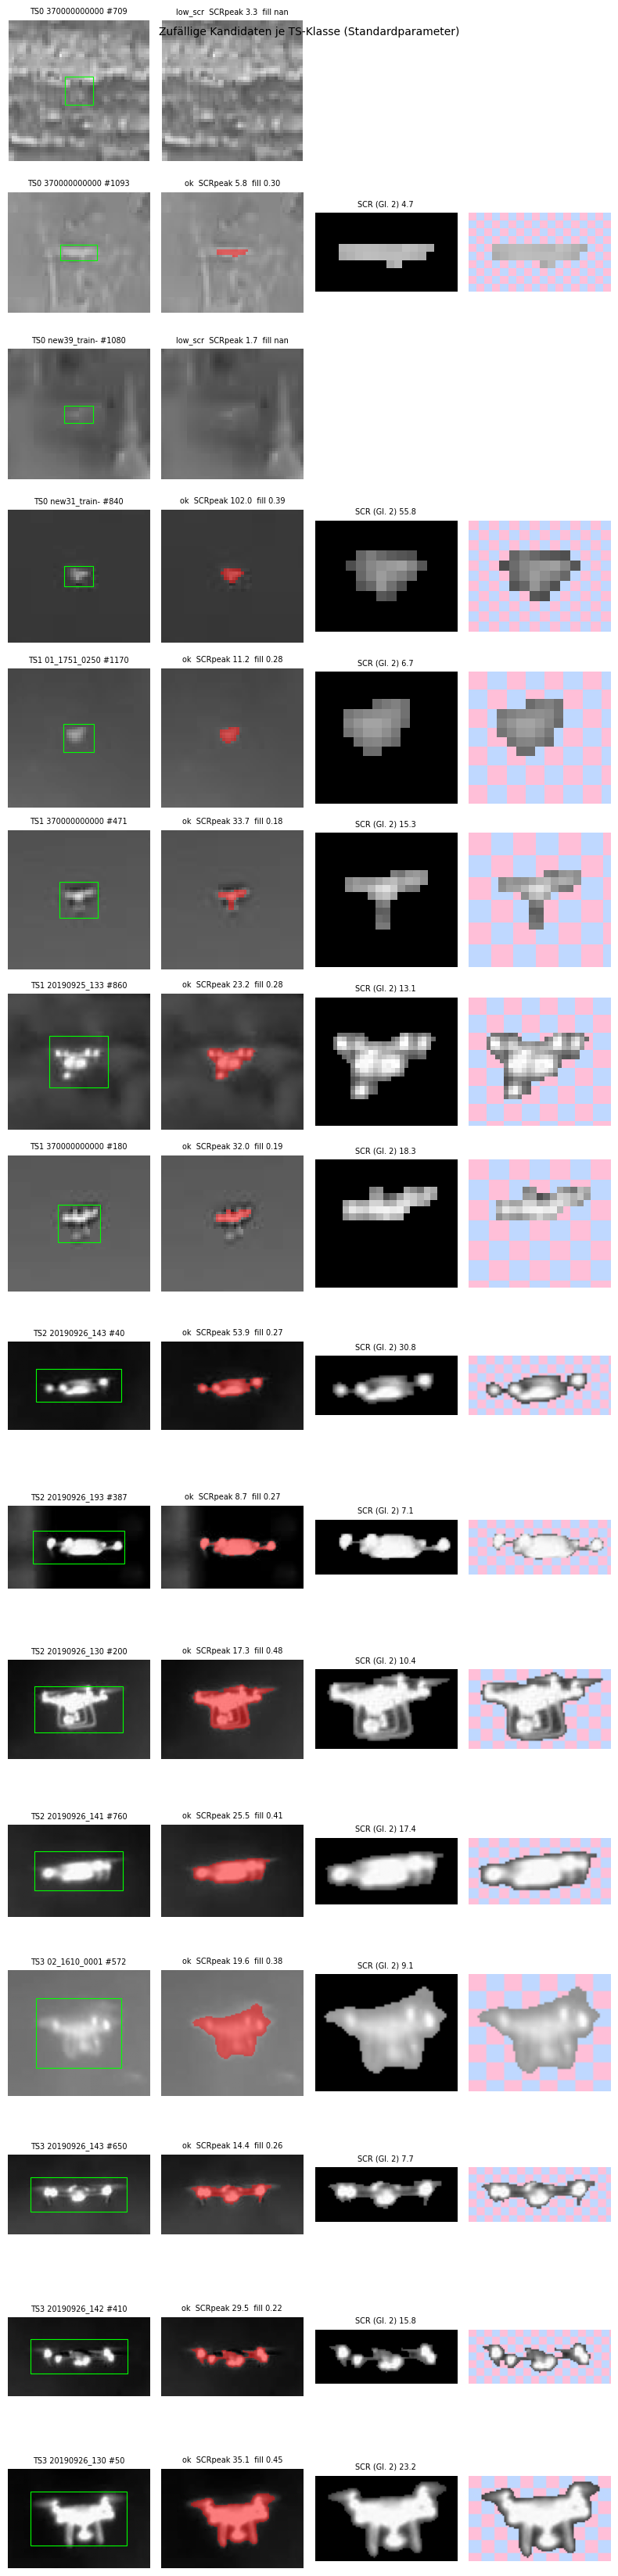

In [14]:
def show_cuts(cands, cfg=CFG, title=""):
    fig, axes = plt.subplots(len(cands), 4, figsize=(8, 2.1 * len(cands)), squeeze=False)
    for row, c in zip(axes, cands):
        cut = segment_target(read_gray(c.record.img_path), c.record.bbox, cfg)
        ox, oy = cut.context_origin
        x, y, w, h = c.record.bbox
        row[0].imshow(cut.context, cmap="gray", vmin=0, vmax=255)
        draw_box(row[0], (x - ox, y - oy, w, h))
        row[1].imshow(overlay(cut.context, cut.context_mask))
        scr = f"{cut.contrast.scr_peak:.1f}" if cut.contrast else "-"
        row[0].set_title(f"TS{c.ts} {c.record.seq[:12]} #{c.record.frame_idx}", fontsize=7)
        row[1].set_title(f"{cut.reason}  SCRpeak {scr}  fill {cut.stats.get('fill', np.nan):.2f}", fontsize=7)
        if cut.ok:
            row[2].imshow(cut.gray, cmap="gray", vmin=0, vmax=255)
            row[3].imshow(on_checkerboard(cut.gray, cut.mask), cmap="gray", vmin=0, vmax=1)
            row[2].set_title(f"SCR (Gl. 2) {cut.stats['scr']:.1f}", fontsize=7)
        for ax in row:
            ax.axis("off")
    fig.suptitle(title, fontsize=10)
    plt.tight_layout()
    plt.show()


rng = np.random.default_rng(SEED)
pick = []
for ts in SIZE_CLASSES:
    cs = [c for c in candidates if c.ts == ts]
    pick += [cs[i] for i in rng.choice(len(cs), min(4, len(cs)), replace=False)]
show_cuts(pick, title="Zufällige Kandidaten je TS-Klasse (Standardparameter)")

### Parameter-Varianten

Grenzfälle aus 300 zufälligen Kandidaten: die 4 mit dem niedrigsten Peak-SCR über `min_scr` und die 4 mit
dem höchsten Füllgrad. Gleiche Kandidaten mit verschiedenen `k_sigma` / `rel_thresh`.

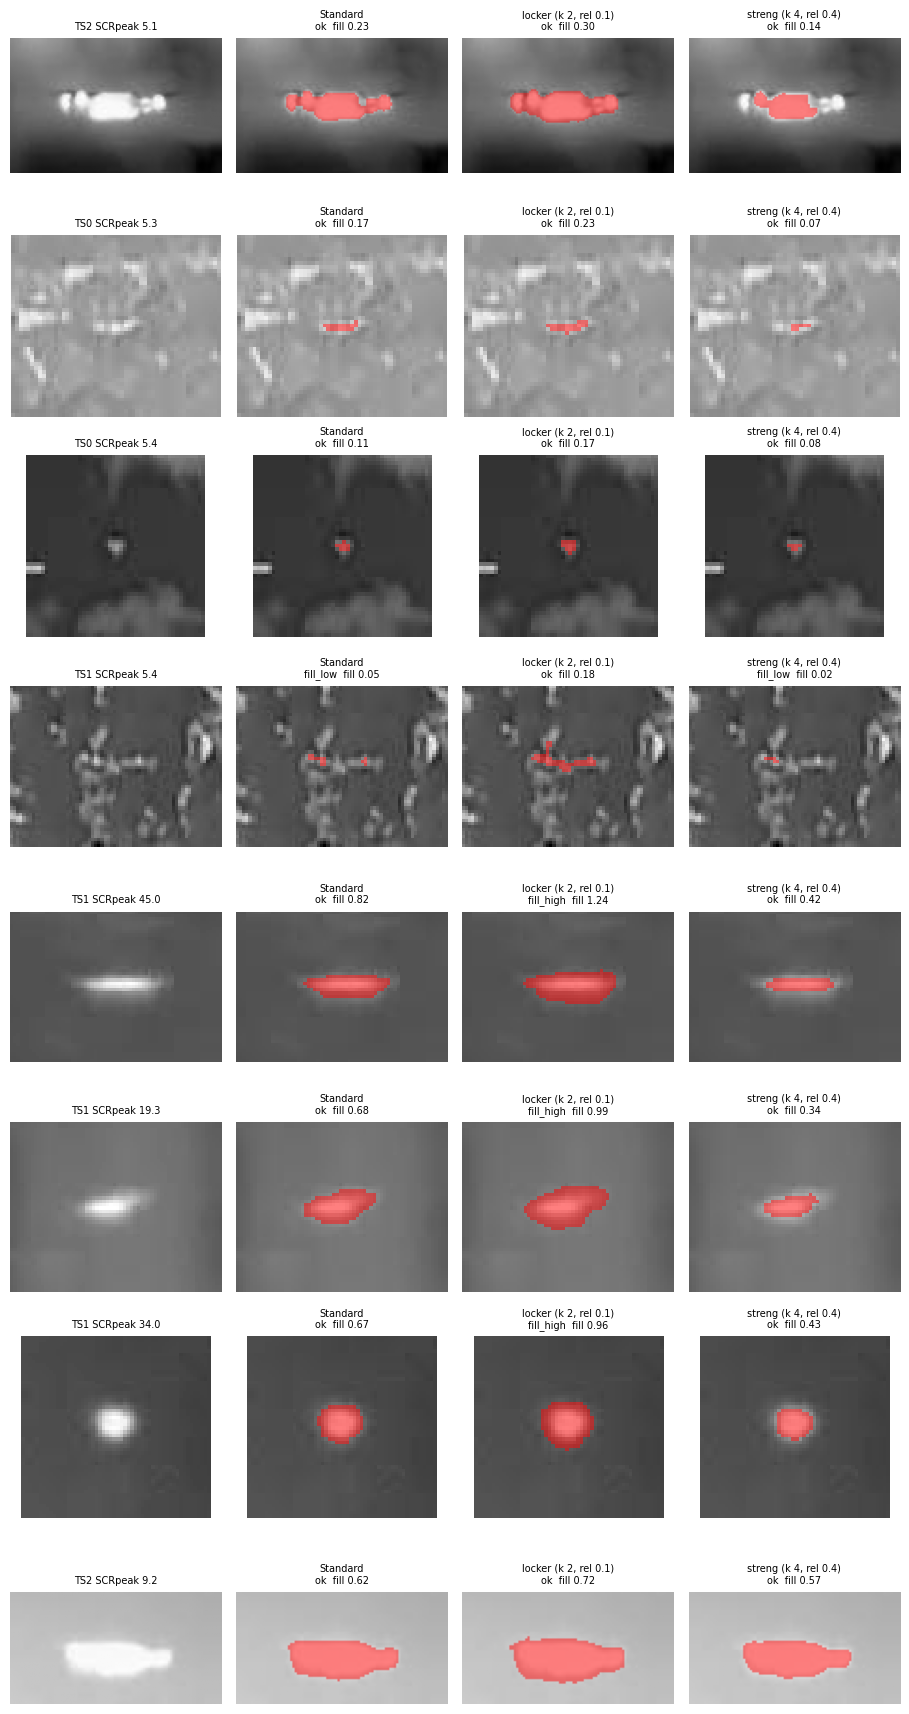

In [15]:
variants = {
    "Standard": CFG,
    "locker (k 2, rel 0.1)": LibraryConfig(k_sigma=2.0, rel_thresh=0.1),
    "streng (k 4, rel 0.4)": LibraryConfig(k_sigma=4.0, rel_thresh=0.4),
}

scored = []
for i in rng.choice(len(candidates), min(300, len(candidates)), replace=False):
    c = candidates[i]
    cut = segment_target(read_gray(c.record.img_path), c.record.bbox, CFG)
    if cut.contrast is not None and cut.contrast.scr_peak >= CFG.min_scr:
        scored.append((cut.contrast.scr_peak, cut.stats.get("fill", np.nan), c))
low_scr = [c for _, _, c in sorted(scored, key=lambda t: t[0])[:4]]
high_fill = [c for _, _, c in sorted((t for t in scored if np.isfinite(t[1])), key=lambda t: -t[1])[:4]]
hard = low_scr + high_fill

fig, axes = plt.subplots(len(hard), 1 + len(variants), figsize=(2.3 * (1 + len(variants)), 2.2 * len(hard)), squeeze=False)
for row, c in zip(axes, hard):
    img = read_gray(c.record.img_path)
    for ax, (name, cfg) in zip(row[1:], variants.items()):
        cut = segment_target(img, c.record.bbox, cfg)
        ax.imshow(overlay(cut.context, cut.context_mask))
        ax.set_title(f"{name}\n{cut.reason}  fill {cut.stats.get('fill', np.nan):.2f}", fontsize=7)
    row[0].imshow(cut.context, cmap="gray", vmin=0, vmax=255)
    row[0].set_title(f"TS{c.ts} SCRpeak {cut.contrast.scr_peak:.1f}", fontsize=7)
    for ax in row:
        ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Bibliothek bauen

`build_library` schreibt nach `data/library/`:

- `targets/<Datensatz>__<Sequenz>__<Frame>.png`: Grau + Alpha („LA“), außerhalb der Maske schwarz und transparent
- `library.csv`: eine Zeile pro Ziel (Quelle, Box und Maskenbox im Ausschnitt, TS, Polarität, μ_b, σ_b, SCR, Füllgrad, …)
- `build_info.json`: Konfiguration, Filter-Trichter, Segmentierungs-Ergebnisse

Ein vorhandener Ordner wird **gelöscht und neu geschrieben**, aber nur mit `overwrite=True` und nur, wenn darin
`build_info.json` liegt. `REBUILD = False` lädt nur die vorhandene Bibliothek.

In [16]:
REBUILD = True

if REBUILD or not (LIBRARY_DIR / "library.csv").exists():
    lib = build_library(CFG, overwrite=True)
else:
    lib = load_library()
info = json.loads((LIBRARY_DIR / "build_info.json").read_text())
display(pd.DataFrame(info["funnel"]))  # Spalten = Datensätze
display(pd.Series(info["segmentation"], name="Kandidaten").to_frame())
print(f"{info['n_targets']} Ziele aus {info['n_sequences']} Sequenzen in {info['duration_s']} s -> {LIBRARY_DIR}")

24-11-2026 21:32:58 | INFO    | Deleting existing library /home/jessh/Study/Bachelor-Thesis/data/library
24-11-2026 21:33:01 | INFO    | [train] Anti-UAV410: 213995 frames in 200 sequences (2.7 s)
24-11-2026 21:33:01 | INFO    | Anti-UAV410:
24-11-2026 21:33:03 | INFO    | Candidates: frames 213995 -> with_target 208832 -> no_excluded_tag 208832 -> size_class 208832 -> clear_of_hud_and_border 203681 -> thinned 18641 (200 sequences)
24-11-2026 21:33:04 | INFO    | [train] CST-AntiUAV: 127991 frames in 120 sequences (1.6 s)
24-11-2026 21:33:04 | INFO    | CST-AntiUAV:
24-11-2026 21:33:04 | WARNING | building_1: tag lists incomplete ({'LR': 0, 'VE': 0, 'OC': 925, 'FM': 925, 'SV': 925, 'IC': 0, 'DBC': 925, 'TS': 0} for 925 frames), treated as untagged.
24-11-2026 21:33:04 | WARNING | building_10: tag lists incomplete ({'LR': 0, 'VE': 0, 'OC': 1175, 'FM': 1175, 'SV': 1175, 'IC': 0, 'DBC': 1175, 'TS': 0} for 1175 frames), treated as untagged.
24-11-2026 21:33:04 | WARNING | building_11: tag 

,Anti-UAV410,CST-AntiUAV
frames,213995,127991
with_target,208832,109916
no_excluded_tag,208832,109916
size_class,208832,109916
clear_of_hud_and_border,203681,95979
thinned,18641,9303
saved,15136,4713


,Kandidaten
ok,19849
low_scr,7731
fill_high,220
fill_low,131
tiny_mask,13


19849 Ziele aus 311 Sequenzen in 43.4 s -> /home/jessh/Study/Bachelor-Thesis/data/library


## 5. Bibliothek analysieren

In [17]:
display(lib.groupby(["dataset", "polarity"]).size().rename("Ziele").to_frame())
display(lib.groupby("ts").size().rename(index=SIZE_CLASSES).rename("Ziele").to_frame())
display(lib.polarity.value_counts().rename("Ziele").to_frame())
print(f"gesättigt: {lib.saturated.mean():.1%}")
print(f"kleines Ziel nach PGDA (Flächenverhältnis < 0.15 %): {(lib.area_ratio < 0.0015).mean():.1%}")
lib.groupby(["dataset", "seq"]).size().describe().round(1).rename("Ziele je Sequenz").to_frame()

Ziele
dataset     polarity       
Anti-UAV410 bright    14986
            dark        150
CST-AntiUAV bright     4655
            dark         58

,Ziele
ts,
<=10 px,3433
10-30 px,6968
30-50 px,7205
>50 px,2243


,Ziele
polarity,
bright,19641
dark,208


gesättigt: 56.0%
kleines Ziel nach PGDA (Flächenverhältnis < 0.15 %): 66.6%


,Ziele je Sequenz
count,311.0
mean,63.8
std,31.5
min,1.0
25%,38.0
50%,71.0
75%,92.0
max,100.0


### Vergleich mit dem ganzen Train-Split

Verglichen wird der Anti-UAV410-Teil der Bibliothek (`lib_ds`) mit allen Anti-UAV410-Zielen. Die Einordnung
unten stammt aus der ersten Bibliothek (nur getaggte, saubere Frames) und ist nach dem Neubau neu zu prüfen.

Train = alle 200 Sequenzen, alle Ziele (Größe aus den Boxen, Peak-SCR auf 10 Frames je Sequenz).

- **Größe**: die Bibliothek ist deutlich *kleiner* als der Train-Split. Getaggt sind vor allem die neueren
  Sequenzen mit kleinen Drohnen; die ungetaggten `2019092*`-Aufnahmen haben große Ziele (√Fläche 30–60 px).
  Für PGDA (kleine Ziele, Flächenverhältnis < 0.15 %) ist das günstig.
- **Kontrast**: die Bibliothek schneidet unten bei `min_scr` ab; der Train-Split hat dort einen eigenen Gipfel
  (schwache Ziele). Darüber sind die Verteilungen ähnlich.
- SCR nach Gl. 2 (Mittelwert über die Maske) liegt erwartungsgemäß unter dem Peak-SCR.

Das volle PGDA gleicht die Verzerrung aus: es skaliert die Ziele auf die Flächenverteilung A und passt die
Intensität an die SCR-Verteilung S des Train-Splits an.

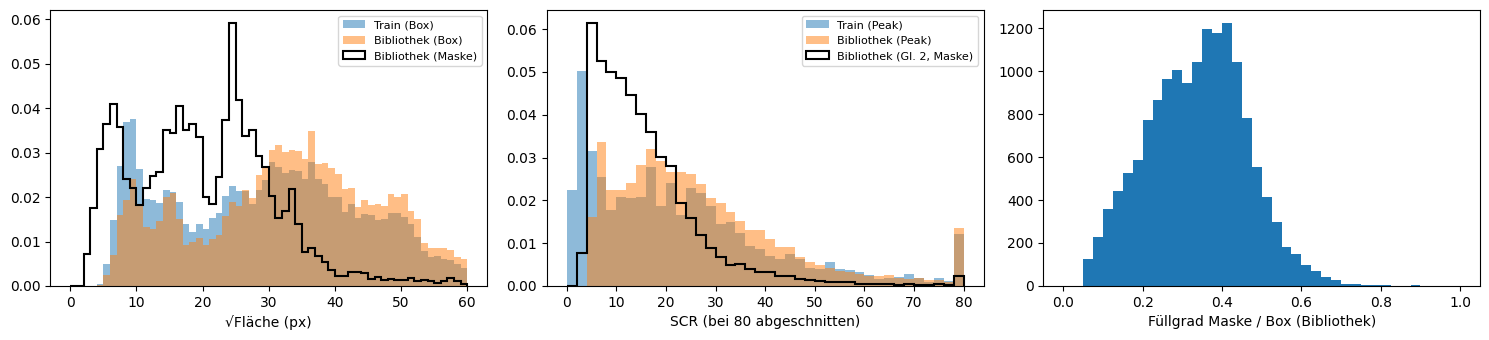

,Train √Fläche (Box),Bib. √Fläche (Box),Bib. √Fläche (Maske),Train Peak-SCR,Bib. Peak-SCR,Bib. SCR (Gl. 2),Bib. Flächenverh. (%)
count,208832.00,15136.00,15136.00,1981.00,15136.00,15136.00,15136.00
mean,30.73,34.39,20.01,24.22,27.62,16.07,0.16
std,16.21,15.77,10.57,23.81,21.02,12.01,0.16
min,1.00,4.90,2.00,0.44,5.00,2.90,0.00
25%,16.58,24.00,11.70,7.46,14.50,8.13,0.04
50%,30.59,34.29,19.31,19.32,23.08,13.29,0.11
75%,41.28,44.41,26.83,32.14,34.81,20.28,0.22
max,125.57,106.24,64.04,234.66,254.03,166.04,1.25


In [18]:
lib_ds = lib[lib.dataset == DS.value]
all_boxes = train[train.has_box]
all_smp = add_contrast(per_seq_sample(all_boxes, 10))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
bins = np.linspace(0, 60, 61)
axes[0].hist(np.sqrt(all_boxes.w * all_boxes.h), bins=bins, density=True, alpha=0.5, label="Train (Box)")
axes[0].hist(np.sqrt(lib_ds.box_w * lib_ds.box_h), bins=bins, density=True, alpha=0.5, label="Bibliothek (Box)")
axes[0].hist(np.sqrt(lib_ds.mask_px), bins=bins, density=True, histtype="step", lw=1.5, color="k", label="Bibliothek (Maske)")
axes[0].set_xlabel("√Fläche (px)")
bins = np.linspace(0, 80, 41)
axes[1].hist(all_smp.scr_peak.clip(upper=80), bins=bins, density=True, alpha=0.5, label="Train (Peak)")
axes[1].hist(lib_ds.scr_peak.clip(upper=80), bins=bins, density=True, alpha=0.5, label="Bibliothek (Peak)")
axes[1].hist(lib_ds.scr.clip(upper=80), bins=bins, density=True, histtype="step", lw=1.5, color="k", label="Bibliothek (Gl. 2, Maske)")
axes[1].set_xlabel("SCR (bei 80 abgeschnitten)")
axes[2].hist(lib_ds.fill, bins=np.linspace(0, 1, 41))
axes[2].set_xlabel("Füllgrad Maske / Box (Bibliothek)")
for ax in axes[:2]:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

pd.DataFrame({
    "Train √Fläche (Box)": np.sqrt(all_boxes.w * all_boxes.h).describe(),
    "Bib. √Fläche (Box)": np.sqrt(lib_ds.box_w * lib_ds.box_h).describe(),
    "Bib. √Fläche (Maske)": np.sqrt(lib_ds.mask_px).describe(),
    "Train Peak-SCR": all_smp.scr_peak.describe(),
    "Bib. Peak-SCR": lib_ds.scr_peak.describe(),
    "Bib. SCR (Gl. 2)": lib_ds.scr.describe(),
    "Bib. Flächenverh. (%)": (100 * lib_ds.area_ratio).describe(),
}).round(2)

### Galerie

48 zufällige Ziele auf Schachbrett (= transparent), jedes auf gleiche Anzeigegröße skaliert. Titel: TS-Klasse und SCR (Gl. 2).

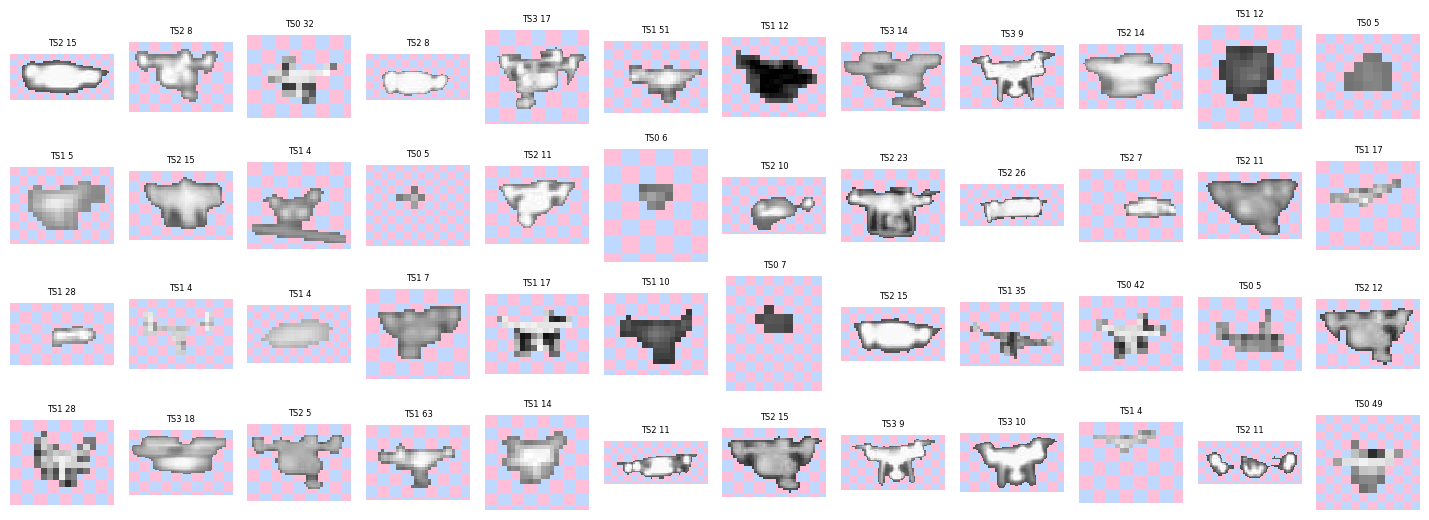

In [19]:
def gallery(df, n=48, cols=12, seed=SEED):
    rows = df.sample(min(n, len(df)), random_state=seed)
    n_rows = int(np.ceil(len(rows) / cols))
    fig, axes = plt.subplots(n_rows, cols, figsize=(cols * 1.2, n_rows * 1.35), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, r in zip(axes.flat, rows.itertuples(index=False)):
        gray, mask = read_cutout(r.path)
        ax.imshow(on_checkerboard(gray, mask), cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        ax.set_title(f"TS{r.ts} {r.scr:.0f}", fontsize=6)
    plt.tight_layout()
    plt.show()


gallery(lib)

## 6. Vorschau: Gaussian paste

PGDA-Schritt „Gaussian paste“ (`gaussian_paste`): Gewichte = Gauß-geglättete Maske, auf max 1 normiert und nur
auf den Zielpixeln (sonst würde der schwarze Ausschnitt-Hintergrund mit eingemischt). Mischung
I' = w·T + (1 − w)·I mit `acb.fuse`. σ = 0 ist die harte Maske.

Noch **ohne** SCR-Anpassung und ohne Subfigure-Split: das Ziel behält seine Originalintensität. Hintergründe sind
zufällige Train-Frames aus allen Sequenzen. Die Positionen liegen unterhalb des HUD-Bands und überlappen die GT-Box nicht.

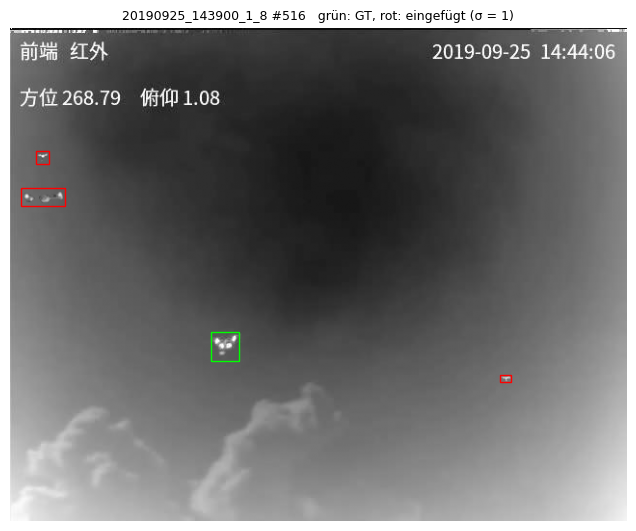

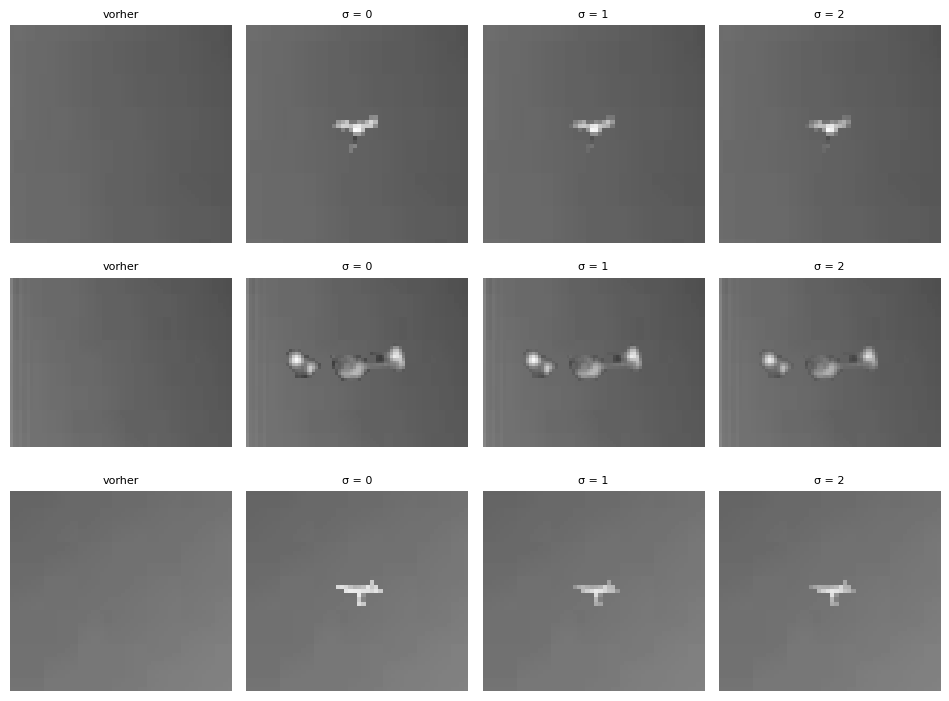

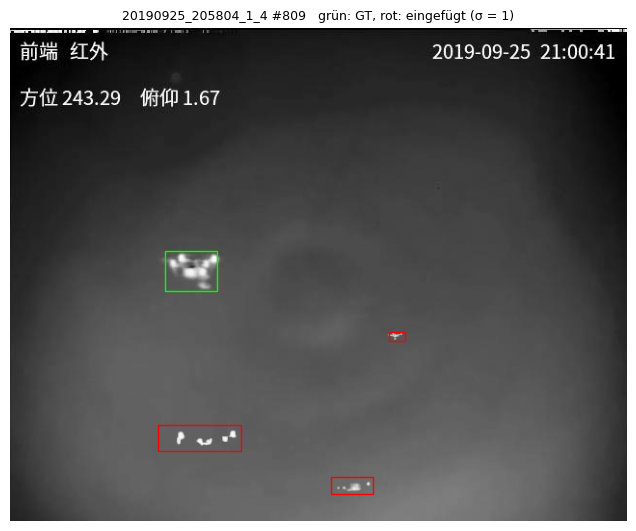

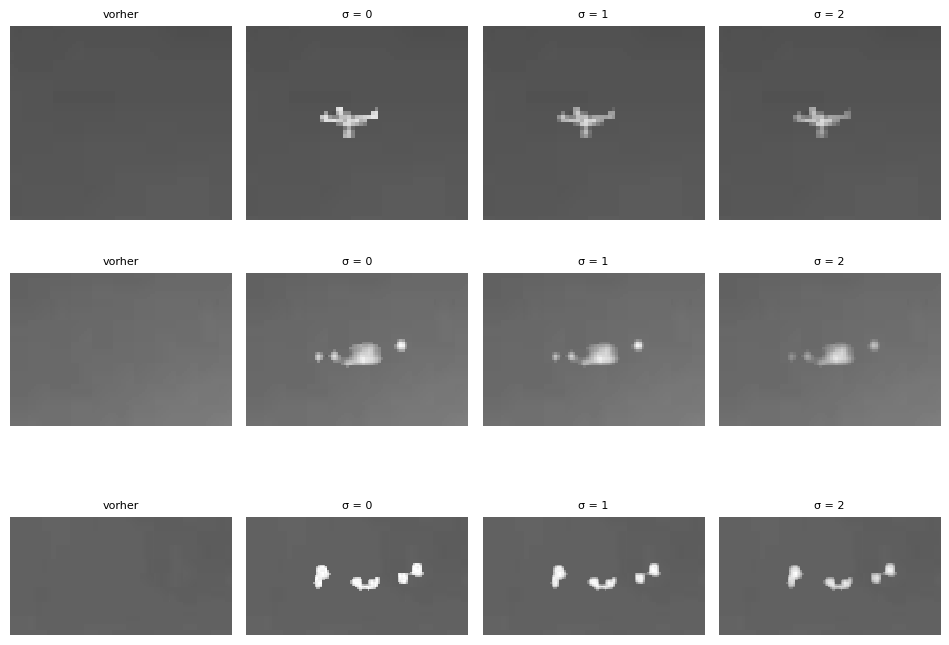

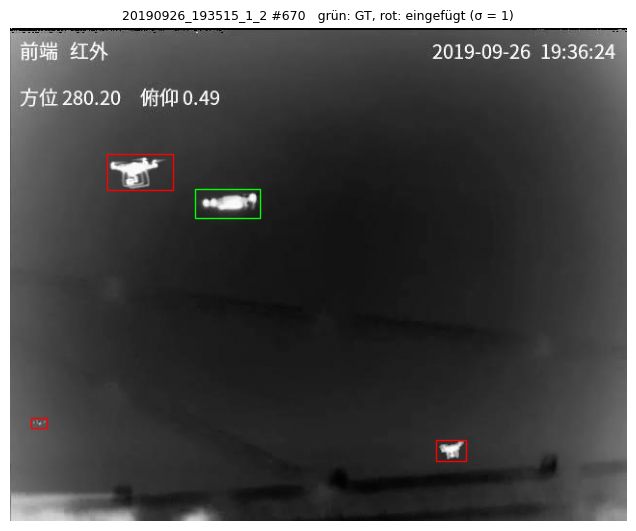

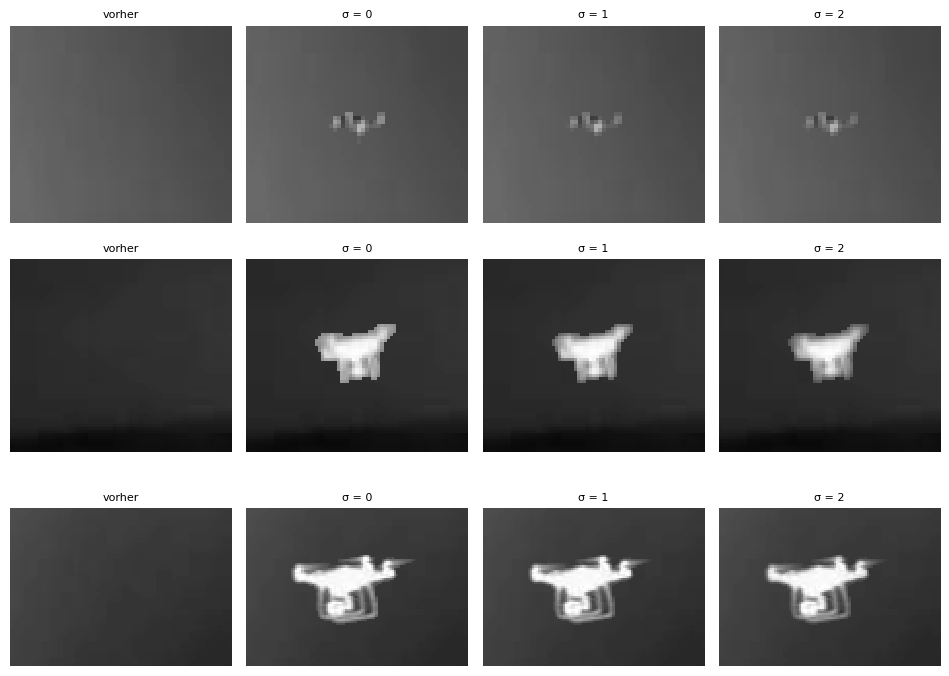

In [20]:
SIGMAS = (0.0, 1.0, 2.0)
N_FRAMES, N_PASTE = 3, 3
rng = np.random.default_rng(SEED)


def overlaps(a, b):  # (x0, y0, x1, y1)
    return a[0] < b[2] and b[0] < a[2] and a[1] < b[3] and b[1] < a[3]


def plan_pastes(img, gt, n, rng, hud_rows=CFG.hud_rows, tries=50):
    # Zufällige Ziele + Positionen; für alle σ gleich, damit nur die Gewichtung variiert
    H, W = img.shape
    occupied = [] if gt is None else [(gt[0], gt[1], gt[0] + gt[2], gt[1] + gt[3])]
    plan = []
    for i in rng.choice(len(lib), n, replace=False):
        r = lib.iloc[i]
        gray, mask = read_cutout(r.path)
        h, w = gray.shape
        for _ in range(tries):
            x, y = int(rng.integers(0, W - w)), int(rng.integers(hud_rows, H - h))
            if not any(overlaps((x, y, x + w, y + h), o) for o in occupied):
                occupied.append((x, y, x + w, y + h))
                plan.append((gray, mask, x, y, (r.box_x, r.box_y, r.box_w, r.box_h)))
                break
    return plan


for fr in train.sample(N_FRAMES, random_state=SEED).itertuples(index=False):
    img = read_gray(fr.img_path)
    gt = (fr.x, fr.y, fr.w, fr.h) if fr.has_box else None
    plan = plan_pastes(img, gt, N_PASTE, rng)
    results = {}
    for s in SIGMAS:
        out, boxes = img, []
        for gray, mask, x, y, box in plan:
            out, b = gaussian_paste(out, gray, mask, x, y, sigma=s, box=box)
            boxes.append(b)
        results[s] = out

    fig, ax = plt.subplots(figsize=(8, 6.4))
    ax.imshow(results[1.0], cmap="gray", vmin=0, vmax=255)
    if gt is not None:
        draw_box(ax, gt, "lime", 1)
    for b in boxes:
        draw_box(ax, b, "red", 1)
    ax.set_title(f"{fr.seq} #{fr.frame_idx}   grün: GT, rot: eingefügt (σ = 1)", fontsize=9)
    ax.axis("off")
    plt.show()

    fig, axes = plt.subplots(len(plan), len(SIGMAS) + 1, figsize=(2.4 * (len(SIGMAS) + 1), 2.4 * len(plan)), squeeze=False)
    for row, b in zip(axes, boxes):
        crop, _ = crop_around(img, b, 20)
        row[0].imshow(crop, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        row[0].set_title("vorher", fontsize=8)
        for ax, s in zip(row[1:], SIGMAS):
            crop, _ = crop_around(results[s], b, 20)
            ax.imshow(crop, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
            ax.set_title(f"σ = {s:g}", fontsize=8)
        for ax in row:
            ax.axis("off")
    plt.tight_layout()
    plt.show()

## 7. PGDAA (PGDA adaptiert)

`PGDAA` in `src/augmentations/sota.py` setzt Algorithmus 1 von Wang et al. (2022) als Albumentations-Transform um.
Mit Wahrscheinlichkeit p wird das Trainingsbild **ersetzt** durch ein synthetisches Bild:

1. Hintergrund B_o: zufälliger Train-Frame **ohne** Ziel; Subfigure-Split = zufälliger Ausschnitt (Seitenanteil
   `crop_scale`), auf Frame-Größe hochskaliert.
2. Je Ziel (`num_targets`): zufälliges **helles** Bibliotheksziel → Flip/Affin (gt) → Elastic/Grid/Piecewise (nt) →
   Skalierung, sodass sein Box-Flächenverhältnis aus **A** stammt (±10 %) → Gaussian paste (gp).
3. SCR perception: SCR des Ziels gegen die Umgebung R (Radius d = 20) an der Einfügestelle. Liegt er außerhalb von
   **S**, wird die Zielintensität auf einen zufälligen Wert aus S verschoben (danach ColorJitter).
4. Boxen = nur die eingefügten Ziele.

Prioren: **A** = Box-Flächenverhältnisse aller Train-Boxen < 0.15 %, **S** = SCR (Gl. 2) der Bibliothek, 20.–80. Perzentil.
Abweichungen vom Paper (Pseudo-Masken, online statt offline, Box statt Pixel in Gl. 1, …) stehen im Docstring von `sota.py`.

24-11-2026 21:33:49 | INFO    | [train] Anti-UAV410: 213995 frames in 200 sequences (2.6 s)
24-11-2026 21:33:51 | INFO    | [train] CST-AntiUAV: 127991 frames in 120 sequences (1.8 s)
/home/jessh/Study/Bachelor-Thesis/.venv/lib/python3.10/site-packages/albumentations/core/validation.py:114: UserWarning: This augmenter is very slow. Try to use ``ElasticTransform`` instead, which is at least 10x faster.
  original_init(self, **validated_kwargs)
24-11-2026 21:33:53 | INFO    | PGDAA: T = 19641 bright library targets (of 19849), S = 11909 SCR values in [6.68, 25.99] (percentiles (20.0, 80.0)), A = 173326 area ratios < 0.0015, B_O = 23238 pure-background frames


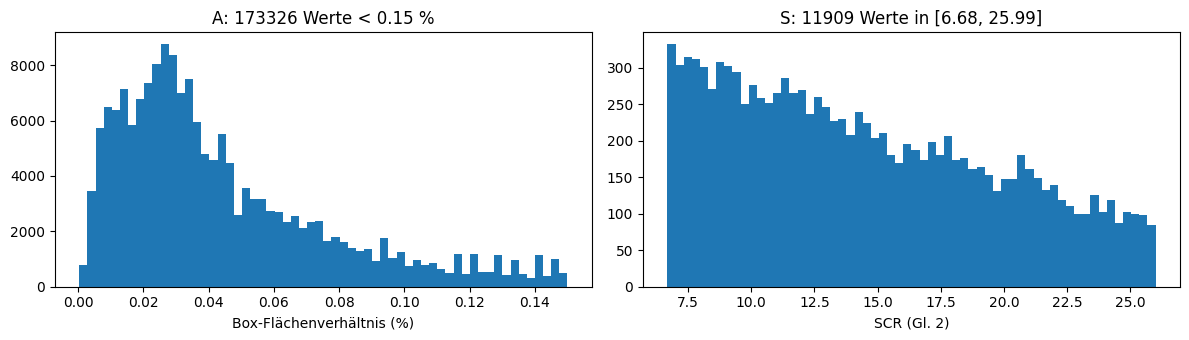

In [21]:
records = [r for ds in DatasetName for r in load_dataset_split(ds, "train")]
pgdaa = PGDAA(records, num_targets=[1, 3], p=1.0)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(100 * pgdaa.A, bins=60)
axes[0].set_xlabel("Box-Flächenverhältnis (%)")
axes[0].set_title(f"A: {len(pgdaa.A)} Werte < {100 * pgdaa.max_area_ratio:g} %")
axes[1].hist(pgdaa.S, bins=60)
axes[1].set_xlabel("SCR (Gl. 2)")
axes[1].set_title(f"S: {len(pgdaa.S)} Werte in [{pgdaa.S.min():.2f}, {pgdaa.S.max():.2f}]")
plt.tight_layout()
plt.show()

### Synthetische Bilder

Je Bild die eingefügten Boxen (rot) und darunter ein Zoom auf jedes Ziel (Box ± 20 px).

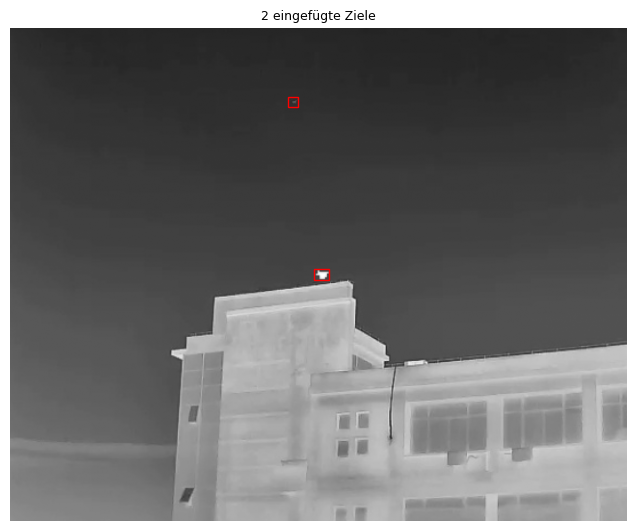

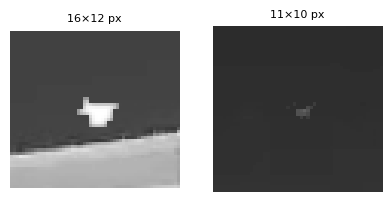

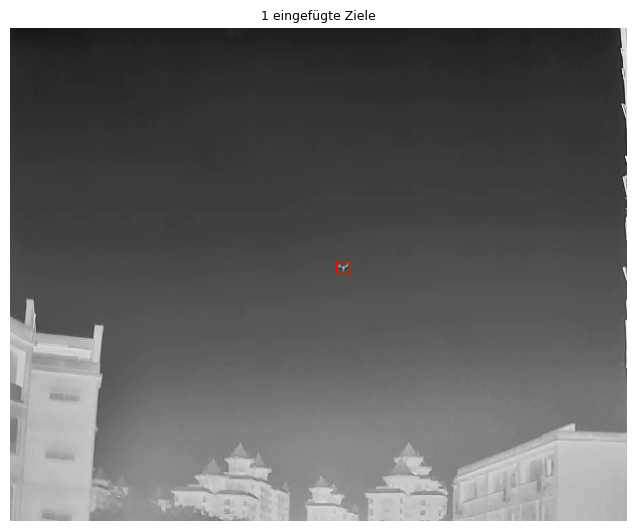

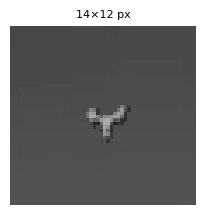

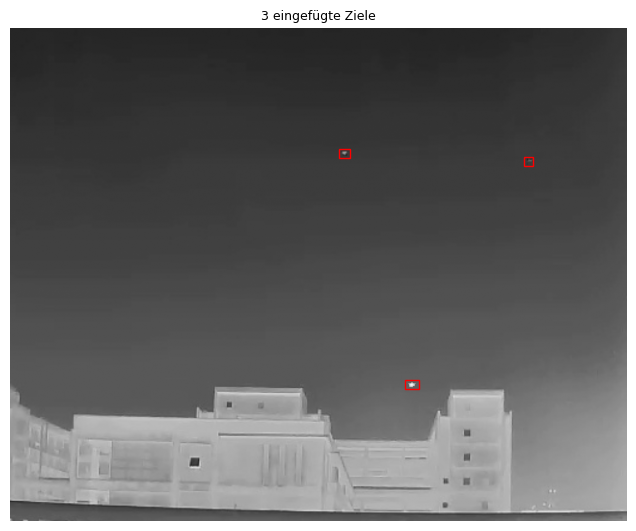

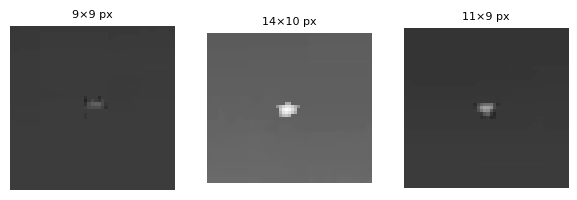

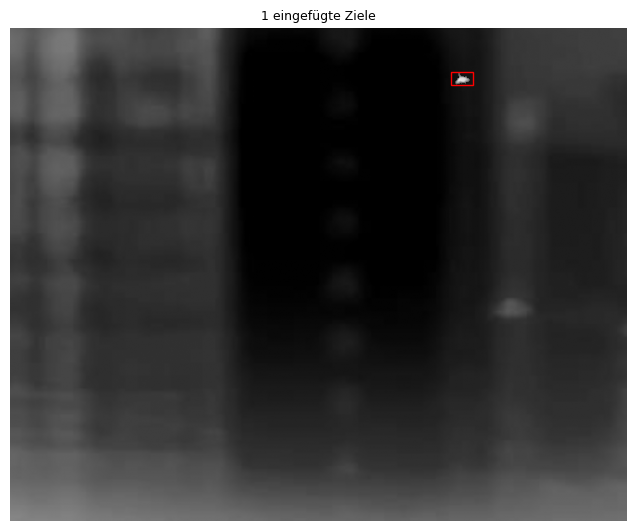

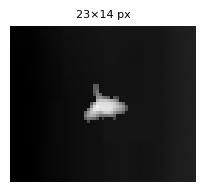

In [22]:
import albumentations as A


def synth(transform, n, seed=SEED):
    comp = A.Compose([transform], bbox_params=A.BboxParams(format="coco", label_fields=["class_labels"]))
    comp.set_random_seed(seed)
    dummy = np.zeros((512, 640), np.uint8)  # wird ersetzt; nur die Größe zählt
    return [comp(image=dummy, bboxes=[], class_labels=[]) for _ in range(n)]


for out in synth(pgdaa, 4):
    img, boxes = out["image"], [tuple(b) for b in out["bboxes"]]
    fig, ax = plt.subplots(figsize=(8, 6.4))
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    for b in boxes:
        draw_box(ax, b, "red", 1)
    ax.set_title(f"{len(boxes)} eingefügte Ziele", fontsize=9)
    ax.axis("off")
    plt.show()
    fig, axes = plt.subplots(1, len(boxes), figsize=(2.4 * len(boxes), 2.4), squeeze=False)
    for ax, b in zip(axes[0], boxes):
        crop, _ = crop_around(img, b, 20)
        ax.imshow(crop, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        ax.set_title(f"{b[2]:.0f}×{b[3]:.0f} px", fontsize=8)
        ax.axis("off")
    plt.show()

### Ablation (Paper, Tabelle V)

Gleicher Seed, nur ein Baustein ausgeschaltet: ohne Subfigure-Split (ganzer Hintergrund-Frame, Ziele in
Bibliotheksgröße), ohne SCR perception, harte Maske statt Gaussian paste (σ = 0).

/home/jessh/Study/Bachelor-Thesis/.venv/lib/python3.10/site-packages/albumentations/core/validation.py:114: UserWarning: This augmenter is very slow. Try to use ``ElasticTransform`` instead, which is at least 10x faster.
  original_init(self, **validated_kwargs)
24-11-2026 21:33:56 | INFO    | PGDAA: T = 19641 bright library targets (of 19849), S = 11909 SCR values in [6.68, 25.99] (percentiles (20.0, 80.0)), A = 173326 area ratios < 0.0015, B_O = 23238 pure-background frames
/home/jessh/Study/Bachelor-Thesis/.venv/lib/python3.10/site-packages/albumentations/core/validation.py:114: UserWarning: This augmenter is very slow. Try to use ``ElasticTransform`` instead, which is at least 10x faster.
  original_init(self, **validated_kwargs)
24-11-2026 21:33:58 | INFO    | PGDAA: T = 19641 bright library targets (of 19849), S = 11909 SCR values in [6.68, 25.99] (percentiles (20.0, 80.0)), A = 173326 area ratios < 0.0015, B_O = 23238 pure-background frames
/home/jessh/Study/Bachelor-Thesis/.ven

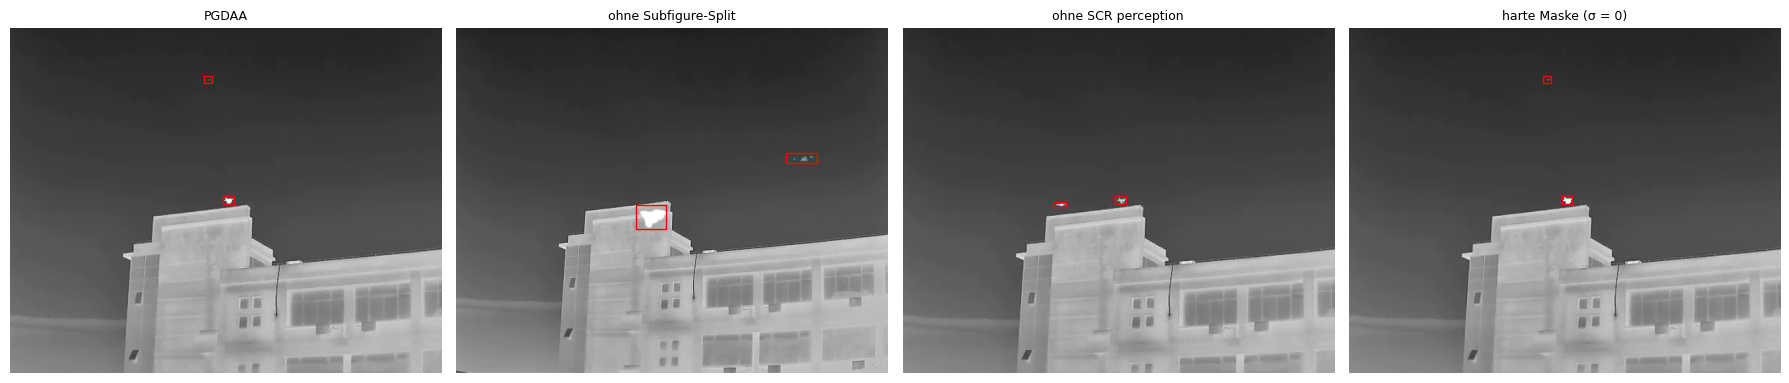

In [23]:
variants = {
    "PGDAA": {},
    "ohne Subfigure-Split": {"subfigure_split": False},
    "ohne SCR perception": {"scr_perception": False},
    "harte Maske (σ = 0)": {"gaussian_sigma": 0.0},
}
fig, axes = plt.subplots(1, len(variants), figsize=(4.5 * len(variants), 3.8))
for ax, (name, kw) in zip(axes, variants.items()):
    out = synth(PGDAA(records, num_targets=[1, 3], p=1.0, **kw), 1)[0]
    ax.imshow(out["image"], cmap="gray", vmin=0, vmax=255)
    for b in out["bboxes"]:
        draw_box(ax, tuple(b), "red", 1)
    ax.set_title(name, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()